# Airflow ELT demo: drive the pipeline from a notebook

This notebook runs the demo through Airflow's REST API and reads the results from the warehouse. Every
action here is also a button in the Airflow UI (http://localhost:8080); keep both open side by side.

1. **Load a month** and watch its tasks.
2. **The quality gate's verdict**, read from the audit table.
3. **Data-aware scheduling:** the passing month's asset event starts `taxi_transform` (dbt).
4. **What landed** in the marts.
5. **Break a month** with an injected fault and watch the gate stop it.
6. **Fix and recover:** remove the fault, rerun from `load_raw`, and the month flows through.

**Where it runs:** the local Compose stack (`make up`), or the AWS demo through `deploy/tunnel.sh`,
which forwards the same two ports. Credentials come from `.env`, or from `AIRFLOW_PASSWORD` and
`WAREHOUSE_PASSWORD` in the environment (printed by `deploy/up.sh`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from airflow_demo import Airflow, sql
from IPython.display import Image, display

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)
MONTH_GOOD = "2024-05"     # a month to load cleanly (any published month works; reloading is safe)
MONTH_BAD = "2024-06"      # a month to corrupt on purpose
FAULT = "bad_zones"        # shift_pickups | bad_zones | missing_column (see include/taxi/faults.py)

af = Airflow()
af.unpause("taxi_ingest", "taxi_transform")
af.dags()

,dag_id,is_paused,timetable_description,next_dagrun_run_after
0,taxi_housekeeping,False,"At 00:00, only on Sunday",2026-10-18T00:00:00Z
1,taxi_ingest,False,"At 00:00, on day 1 of the month",2026-11-01T00:00:00Z
2,taxi_transform,False,Triggered by assets,NaN


## The pipeline

`taxi_ingest` runs once per month of data and only a month that passes its quality gate publishes the
`raw_yellow_trips` asset; `taxi_transform` (dbt) runs on that asset, not on a clock.

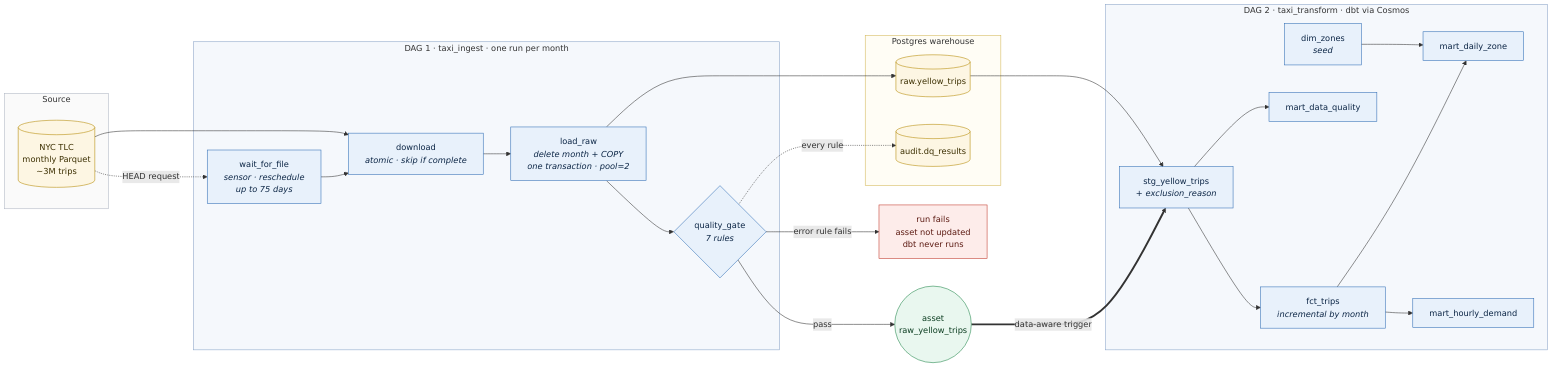

In [2]:
display(Image("../docs/img/workflow.png", width=1100))

## 1. Load a month

A one-month backfill: the same call as `make backfill`, through the API. Watch the tasks move from
queued to running to success; the file is deleted once the month passes the gate.

In [3]:
transform_before = af.latest_run("taxi_transform")["dag_run_id"]
run_id = af.start_month(MONTH_GOOD)
af.watch("taxi_ingest", run_id)

taxi_ingest / backfill__2024-06-01T00:00:00+00:00: ✅ success  (35s)


,,task_id,state,try_number,seconds
0,✅,wait_for_file,success,2,2.0
1,✅,download,success,2,2.0
2,✅,load_raw,success,2,23.0
3,✅,quality_gate,success,2,2.0
4,✅,remove_download,success,2,1.0


'success'

## 2. The quality gate's verdict

Every rule, every load, lands in `audit.dq_results`, pass or fail. Error rules stop a month; warn rules
alert and let it through.

In [4]:
sql('''select rule, round(value::numeric, 4) as value, op, threshold, severity, passed
       from audit.dq_results
       where source_month = %s and checked_at = (select max(checked_at) from audit.dq_results where source_month = %s)
       order by severity, rule''', (f"{MONTH_GOOD}-01", f"{MONTH_GOOD}-01"))

,rule,value,op,threshold,severity,passed
0,dropoff_after_pickup,1.0000,>=,0.9950,error,True
1,pickup_in_month,1.0000,>=,0.9900,error,True
2,row_count,3723833.0000,>=,1000000.0000,error,True
3,zone_ids_valid,1.0000,>=,0.9990,error,True
4,distance_over_200mi,0.0000,<=,0.0005,warn,True
5,negative_fare_share,0.0161,<=,0.0300,warn,True
6,passenger_null_share,0.1087,<=,0.1500,warn,True


## 3. Data-aware scheduling

The gate's success published an asset event, and that event created a `taxi_transform` run. dbt
rebuilds only the months reloaded since its last run, and only months whose latest gate passed.

In [5]:
display(af.asset_events(limit=3))
transform = af.wait_for_new_run("taxi_transform", after=transform_before)
af.watch("taxi_transform", transform["dag_run_id"])

taxi_transform / asset_triggered__2026-10-14T09:25:58.793920+00:00_y5hGux4y: ✅ success  (81s)


,,task_id,state,try_number,seconds
0,✅,dbt.approved_months_run,success,1,5.0
11,✅,dbt.stg_yellow_trips.run,success,1,5.0
13,✅,dbt.taxi_zone_lookup_seed,success,1,5.0
1,✅,dbt.dim_zones.run,success,1,6.0
12,✅,dbt.stg_yellow_trips.test,success,1,12.0
2,✅,dbt.dim_zones.test,success,1,5.0
3,✅,dbt.fct_trips.run,success,1,33.0
7,✅,dbt.mart_data_quality.run,success,1,8.0
8,✅,dbt.mart_data_quality.test,success,1,5.0
4,✅,dbt.fct_trips.test,success,1,6.0


'success'

## 4. What landed

In [6]:
sql('''select q.source_month, q.raw_rows, q.kept_rows, round(100 * q.excluded_share, 1) as excluded_pct,
              a.approved_at is not null as approved
       from marts.mart_data_quality q left join staging.approved_months a using (source_month)
       order by 1''')

,source_month,raw_rows,kept_rows,excluded_pct,approved
0,2024-01-01,2964624,2834740,4.4,True
1,2024-02-01,3007526,2866123,4.7,True
2,2024-03-01,3582628,3397149,5.2,True
3,2024-04-01,3514289,3372886,4.0,True
4,2024-05-01,3723833,3571850,4.1,True
5,2025-01-01,3475226,3205063,7.8,True


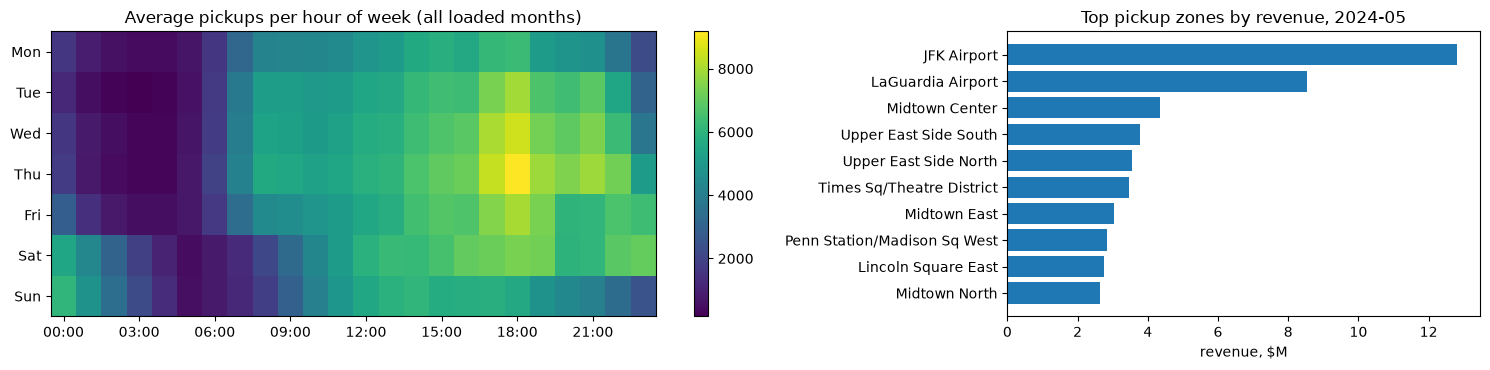

In [7]:
demand = sql("select pickup_dow, pickup_hour, avg_trips from marts.mart_hourly_demand")
grid = demand.pivot(index="pickup_dow", columns="pickup_hour", values="avg_trips").astype(float)
zones = sql('''select zone_name, borough, sum(trips) as trips, round(sum(revenue)) as revenue
               from marts.mart_daily_zone where pickup_date >= %s and pickup_date < %s::date + interval '1 month'
               group by 1, 2 order by revenue desc limit 10''', (f"{MONTH_GOOD}-01", f"{MONTH_GOOD}-01"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
im = a1.imshow(grid.values, aspect="auto", cmap="viridis")
a1.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
a1.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
a1.set_title("Average pickups per hour of week (all loaded months)")
fig.colorbar(im, ax=a1)
a2.barh(zones.zone_name[::-1], zones.revenue[::-1].astype(float) / 1e6)
a2.set_xlabel("revenue, $M")
a2.set_title(f"Top pickup zones by revenue, {MONTH_GOOD}")
plt.tight_layout()
plt.show()

## 5. Break a month

`set_fault` writes the `taxi_fault` Airflow Variable; `load_raw` corrupts that month's source batches
as if TLC had shipped a bad file. With `bad_zones`, 5% of pickup zone ids become 999.

In [8]:
af.set_fault(MONTH_BAD, FAULT)
transform_before = af.latest_run("taxi_transform")["dag_run_id"]
bad_run = af.start_month(MONTH_BAD)
af.watch("taxi_ingest", bad_run)

taxi_ingest / backfill__2024-07-01T00:00:00+00:00: ❌ failed  (30s)


,,task_id,state,try_number,seconds
0,✅,wait_for_file,success,1,2.0
1,✅,download,success,1,2.0
2,✅,load_raw,success,1,20.0
3,❌,quality_gate,failed,1,2.0
4,⛔,remove_download,upstream_failed,0,0.0


'failed'

The gate failed on its first try (`retries=0`: bad data doesn't get better by waiting), the failure
alert fired, the download was kept for investigation, and no asset event was published, so dbt never
ran. The audit table says exactly why:

In [9]:
sql('''select rule, round(value::numeric, 4) as value, op, threshold, severity, passed
       from audit.dq_results
       where source_month = %s and checked_at = (select max(checked_at) from audit.dq_results where source_month = %s)
       order by passed, rule''', (f"{MONTH_BAD}-01", f"{MONTH_BAD}-01"))

,rule,value,op,threshold,severity,passed
0,zone_ids_valid,0.9500,>=,0.9990,error,False
1,distance_over_200mi,0.0000,<=,0.0005,warn,True
2,dropoff_after_pickup,1.0000,>=,0.9950,error,True
3,negative_fare_share,0.0174,<=,0.0300,warn,True
4,passenger_null_share,0.1161,<=,0.1500,warn,True
5,pickup_in_month,1.0000,>=,0.9900,error,True
6,row_count,3539193.0000,>=,1000000.0000,error,True


In [10]:
print("latest taxi_transform run unchanged:", af.latest_run("taxi_transform")["dag_run_id"] == transform_before)
sql("select source_month from staging.approved_months order by 1")

latest taxi_transform run unchanged: True


,source_month
0,2024-01-01
1,2024-02-01
2,2024-03-01
3,2024-04-01
4,2024-05-01
5,2025-01-01


## 6. Fix and recover

"Fix the source" (remove the fault), then clear `load_raw` and everything downstream of it: the same as
**Clear → Downstream** in the UI. The reload replaces the bad rows, the gate passes, the asset event
fires, and dbt picks the month up.

In [11]:
af.delete_fault()
af.rerun_from("taxi_ingest", bad_run, "load_raw")
af.watch("taxi_ingest", bad_run)

taxi_ingest / backfill__2024-07-01T00:00:00+00:00: ✅ success  (30s)


,,task_id,state,try_number,seconds
0,✅,wait_for_file,success,1,2.0
1,✅,download,success,1,2.0
4,✅,load_raw,success,2,22.0
3,✅,quality_gate,success,2,3.0
2,✅,remove_download,success,1,1.0


'success'

In [12]:
transform = af.wait_for_new_run("taxi_transform", after=transform_before)
af.watch("taxi_transform", transform["dag_run_id"])

taxi_transform / asset_triggered__2026-10-14T09:28:24.007810+00:00_W2iiaDmk: ✅ success  (86s)


,,task_id,state,try_number,seconds
13,✅,dbt.taxi_zone_lookup_seed,success,1,6.0
11,✅,dbt.stg_yellow_trips.run,success,1,6.0
0,✅,dbt.approved_months_run,success,1,6.0
12,✅,dbt.stg_yellow_trips.test,success,1,13.0
1,✅,dbt.dim_zones.run,success,1,5.0
2,✅,dbt.dim_zones.test,success,1,5.0
3,✅,dbt.fct_trips.run,success,1,32.0
7,✅,dbt.mart_data_quality.run,success,1,9.0
8,✅,dbt.mart_data_quality.test,success,1,5.0
4,✅,dbt.fct_trips.test,success,1,7.0


'success'

In [13]:
sql('''select f.source_month, count(*) as trips_in_fct, a.approved_at
       from marts.fct_trips f join staging.approved_months a using (source_month)
       group by 1, 3 order by 1''')

,source_month,trips_in_fct,approved_at
0,2024-01-01,2834740,2026-10-14 08:38:03.283916+00:00
1,2024-02-01,2866123,2026-10-14 08:30:24.348455+00:00
2,2024-03-01,3397149,2026-10-14 08:30:41.707231+00:00
3,2024-04-01,3372886,2026-10-14 09:22:20.721743+00:00
4,2024-05-01,3571850,2026-10-14 09:25:57.528974+00:00
5,2024-06-01,3382470,2026-10-14 09:28:21.676969+00:00
6,2025-01-01,3205063,2026-10-14 09:15:35.296292+00:00


## Recap

- **Idempotent loads:** every load replaces its month, so backfills, retries and reruns are safe.
- **Quality gate before transform:** a bad month stops at the gate, is recorded, and never reaches the marts.
- **Data-aware scheduling:** dbt runs because data changed, not because the clock struck.
- **Recovery is an ordinary Airflow action:** fix the cause, clear the task, everything downstream follows.